In [1]:
from sklearn import tree
from sklearn.model_selection import train_test_split
import pandas as pd
import graphviz

In [2]:
# считывание параметров
fileName = input('Введите имя файла с датасетом: ')
num_var = int(input('Выберете ансамблевую технику:\n1 - Bagging\n2 - RandomForest\n3 - AdaBoost\nНомер выбранного варианта: '))
n_estimators = int(input('Количество участников ансамбля: '))
train_size = float(input('Введите значение доли обучающей выборки (от 0 до 1): '))
test_size = 1.0 - train_size

Введите имя файла с датасетом: grades.csv
Выберете ансамблевую технику:
1 - Bagging
2 - RandomForest
3 - AdaBoost
Номер выбранного варианта: 1
Количество участников ансамбля: 70
Введите значение доли обучающей выборки (от 0 до 1): 0.4


In [4]:
# извлечение датасета
dataset = pd.read_csv(fileName,sep=',').replace(' ', '')#.replace('F', 0).replace('M', 1).replace('8A', 81).replace('8B', 82)
dataset.columns = dataset.columns.str.replace(' ', '')
print(dataset)

       age          workclass  fnlwgt    education  education-num  \
0       39          State-gov   77516    Bachelors             13   
1       50   Self-emp-not-inc   83311    Bachelors             13   
2       38            Private  215646      HS-grad              9   
3       53            Private  234721         11th              7   
4       28            Private  338409    Bachelors             13   
...    ...                ...     ...          ...            ...   
32556   27            Private  257302   Assoc-acdm             12   
32557   40            Private  154374      HS-grad              9   
32558   58            Private  151910      HS-grad              9   
32559   22            Private  201490      HS-grad              9   
32560   52       Self-emp-inc  287927      HS-grad              9   

            marital-status          occupation    relationship    race  \
0            Never-married        Adm-clerical   Not-in-family   White   
1       Married-civ-spo

In [5]:
g_voc = {}

for (name, data) in dataset.iteritems():
    isStr = False
    for v in data.values:
        if isStr == True:
            break
        v2 = str(v)
        for c in v2:
            if (ord(c) >= ord('a') and ord(c) <= ord('z')) or (ord(c) >= ord('A') and ord(c) <= ord('Z')):
                isStr = True
                break
    voc = {}
    cnt = 0
    if isStr == True:
        #print(data.values)
        for v in data.values:
            if voc.get(v) == None:
                voc[v] = cnt
                cnt += 1
        for key in voc:
            dataset.loc[dataset[name] == key, name] = voc[key]
        dataset[name] = dataset[name].astype('int')
        g_voc[name] = voc
        """for v in data.values:
            dataset.loc[v] = voc[v]"""
        #print(voc)

print(dataset)

<ipython-input-5-8bf7251d42bb>:3: FutureWarning: iteritems is deprecated and will be removed in a future version. Use .items instead.
  for (name, data) in dataset.iteritems():


       age  workclass  fnlwgt  education  education-num  marital-status  \
0       39          0   77516          0             13               0   
1       50          1   83311          0             13               1   
2       38          2  215646          1              9               2   
3       53          2  234721          2              7               1   
4       28          2  338409          0             13               1   
...    ...        ...     ...        ...            ...             ...   
32556   27          2  257302          6             12               1   
32557   40          2  154374          1              9               1   
32558   58          2  151910          1              9               6   
32559   22          2  201490          1              9               0   
32560   52          6  287927          1              9               1   

       occupation  relationship  race  sex  capital-gain  capital-loss  \
0               0        

In [10]:
# обучение заданного классификатора предсказывать класс значения выбираемой колонки

from sklearn.metrics import accuracy_score,classification_report,confusion_matrix
from sklearn.tree import export_text
from sklearn.ensemble import BaggingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import AdaBoostClassifier

target_col = input('Введите название колонки: ')


data = dataset.drop(target_col, axis=1)          # формирование тензора входных данных
target = dataset[target_col]                  # формирование тензора правильных ответов
data_train, data_test, target_train, target_test = train_test_split(data, target, test_size = test_size)
clf_model = None

if num_var == 1:
    clf_model = BaggingClassifier(KNeighborsClassifier(), n_estimators=n_estimators)
if num_var == 2:
    clf_model = RandomForestClassifier(max_features="sqrt", n_estimators=n_estimators)
if num_var == 3:
    clf_model = AdaBoostClassifier(n_estimators=n_estimators)

clf_model.fit(data_train,target_train)

print("accurancy: " + str(accuracy_score(target_test, clf_model.predict(data_test))))     

Введите название колонки: income
accurancy: 0.7778573987817986


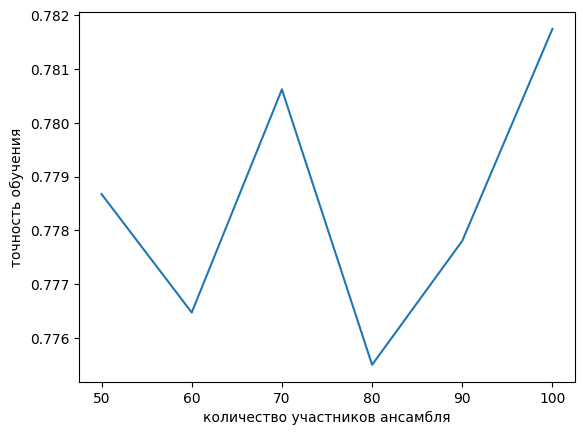

In [11]:
# эксперимент с количеством участников ансамбля
import matplotlib.pyplot as plt

res = []
estms = range(50, 110, 10)
for n_estimators in estms:
    data = dataset.drop(target_col, axis=1)          # формирование тензора входных данных
    target = dataset[target_col]                  # формирование тензора правильных ответов
    data_train, data_test, target_train, target_test = train_test_split(data, target, test_size = test_size)
    clf_model = None
    
    if num_var == 1:
        clf_model = BaggingClassifier(KNeighborsClassifier(), n_estimators=n_estimators)
    if num_var == 2:
        clf_model = RandomForestClassifier(max_features="sqrt", n_estimators=n_estimators)
    if num_var == 3:
        clf_model = AdaBoostClassifier(n_estimators=n_estimators)
    
    clf_model.fit(data_train,target_train)
    res.append(accuracy_score(target_test, clf_model.predict(data_test)))

plt.plot(estms, res)
plt.xlabel('количество участников ансамбля')
plt.ylabel('точность обучения')
plt.show()